### advanced_plotting

Contains relevant plotting and results required for Final Report and Presentation 

- Queensland Government, & Australian Bureau of Metreorology. (1996). SILO - Australian climate data from 1889 to yesterday [Data set]. In Using spatial interpolation to construct a comprehensive archive of Australian climate data. https://doi.org/10.1016/S1364-8152(01)00008-1   


-- Region-based results have now been adjusted to the Grains Research and Development Corporation defined 'Agro-Ecological Zones' 


--- Date:   September 2026

In [1]:
import urllib.request
import urllib.parse
import pandas as pd
import io
import numpy as np
import matplotlib.pyplot as plt
from numpy import trapezoid
import seaborn as sns
import geopandas as gpd
from sklearn.decomposition import PCA
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd

In [2]:
def collect_data(form,lat,lon,start,finish,username="email@gmail.com",password='apirequest'):
    """
    quering and requesting data from SILO using API
    """
    params = {'format': form,
              'lat': lat,
              'lon': lon,
              'start': start,
              'finish': finish,
              'username': username,
              'password': password
             }

    api_url = 'https://www.longpaddock.qld.gov.au/cgi-bin/silo' 
    url = api_url + '/DataDrillDataset.php?' + urllib.parse.urlencode(params)
    
    with urllib.request.urlopen(url) as remote:
        data = remote.read()
        body_str = data.decode('utf-8')
        
    return pd.read_csv(io.StringIO(body_str), skiprows=31, sep=r'\s+')



In [3]:
def clean_data(df):
    """
    converting requested dataset into usable pandas dataset
    - extracting dates in format dd/mm/yyyy
    - converting columns to numeric
    - computing cumulative growing degree days using tmin, tmax and tbase (10)
    """
    df = df.drop(index=0).reset_index(drop=True)
    df['Date2'] = pd.to_datetime(df['Date2'], format='%d/%m/%Y')

    # convert columns to numeric 
    for cols in df.columns:
        if cols != 'Date2':
            try:
                df[cols] = pd.to_numeric(df[cols])
            except (ValueError, TypeError):
                pass

    # extract year, month, day
    df['Year'] = df['Date2'].dt.year
    df['Month'] = df['Date2'].dt.month
    df['Day'] = df['Date2'].dt.day
    # apply GDD calculation
    df['T.Avg'] = (df['T.Max'] + df['T.Min']) / 2
    df['GDD'] = np.where(df['T.Avg'] >= 10, df['T.Avg'] - 10, 0)
    # find cumulative growing degree days
    df['GDD.C'] = df['GDD'].cumsum()
    
    return df

def prepare_data(df, by):
    """
    preparing rainfall and cumulative growing degree set variables 
    - perform smoothing on rainfall observations through rolling window average
    -
    - normalise rainfall observations
    - extract normalised rain and gddc vectors
    """

    clean = clean_data(df)
    # smooth rain values using rolling window average
    clean['Rain.Mean'] = clean.Rain.rolling(window=180,min_periods=1).mean()

    # if wanting to retain normal time based spacing (extracts a weekly point)
    if by == "Time":
        clean_rain = clean[['Rain.Mean']].values[::7]
        clean_gddc = clean[['GDD.C']].values[::7]
    else:
        # generate regular gdd poitns every 100 units
        clean_gddc = np.arange(0, clean.GDD.sum(), 100)
        # estimate rainfall at each of these gdd points
        clean_rain = np.interp(clean_gddc, clean["GDD.C"], clean["Rain.Mean"])

    normalised_rain = []
    min_val = min(clean_rain)
    max_val = max(clean_rain)
    diff = max_val - min_val # normalise through min-max scaling
    for x in clean_rain:
        normalised_rain.append((x - min_val) / diff)
    return np.array(normalised_rain).reshape(len(clean_gddc),1), clean_gddc.reshape(len(clean_gddc),1)




In [4]:
#Testing Rain against GDDc for Merreddin 

start_date = '19710101'
end_date = '20260327'

# Merredin (10092)
# collect data with time based spacing
merre_t_data = collect_data('standard','-31.48','118.28',start_date,end_date,'email@gmail.com')
merre_t_rain, merre_tgddc = prepare_data(merre_t_data, by = "Time")

#collect data with gdd spacing
merre_data = collect_data('standard','-31.48','118.28',start_date,end_date,'email@gmail.com')
merre_rain, merre_gddc = prepare_data(merre_data, by = "")

In [5]:
class ESN:
    """
    N: number of nodes 
    d: average number of connections per node
    rho: spectral radius
    """
    def __init__(self, N, d, rho, input_scaling):
        self.N = N
        self.d = d
        self.rho = rho
        self.a = input_scaling


        # random, sparse, reservoir weights:
        ## connections between nodes decided by probability of d/N
        # sampling from normal distribution provides random weight values.
        Weights = np.multiply(
            np.random.binomial(size=(self.N,self.N), p=self.d/self.N, n=1),
            np.random.normal(size=(self.N,self.N)))
        
        # rescale so that rho = largest absolutel eigenvalue (maintaining echo state property)
        self.Vadj = Weights * (self.rho/np.max(np.absolute(np.linalg.eig(Weights)[0])))

        # input matrix: maps the scalar input to every node of the reservoir
        self.Vin = self.a * np.random.uniform(-1,1,size=(1, self.N))

        # bias matrix: bias added to each node's activation
        self.Vbias = np.random.uniform(-1,1,size=(1,self.N))

    def run_reservoir(self,input_data):
        """
        drive the reservoir using the input_data and return the state at every timestep
        states = (len(input_data), N)
        - comments keep track of matrix multiplications
        """
        states = np.zeros((len(input_data)+1, self.N)) # (timesteps x N)
        for i in range(1, len(input_data)+1): # start at 1 to access previous reservoir state
            states[i, :] = np.tanh(
                np.dot(states[i-1:i, :], self.Vadj) + # (1,N) x (N,N) = (1,N)
                np.dot(input_data[i-1:i], self.Vin) +  # (1,1) x (1,N) = (1,N)
                self.Vbias)
        return states[1:,:] # (timesteps x N), skip first row as it stays zero due to no input being processed. 
      

    def train(self, train_input, train_target, washout, beta=0.01):
        """
        fit the output weights
        - remove the initial washout period from the states and target 
        - compute Vout through ridge regression
        """
        train_states = self.run_reservoir(train_input)
        # removing the washout period 
        train_states = train_states[washout:,:] 
        train_target = train_target[washout:,]

        # using ridge regression to compute the output weights through training
        self.Vout = np.dot(
            np.linalg.pinv(np.dot(train_states.T,train_states) + beta*np.identity(self.N)), #(N,t) x (t,N) = (N,N) + (N,N)
                           np.dot(train_states.T, train_target)) #(N,t) x (t,1) = (N,1)
                           #Vout = (N,1)

        return self.Vout
                           

    def freerun(self, test_input, steps):
        """
        method to perform freerun prediction
        - train the reservoir computer on some testing input data 
        - following training, the readout prediction replaces the input data
        - ESN will form predictions just using previous predictions, with no new information being processed.  
        """
        readout = self.run_reservoir(test_input) 
        freerun_states = np.zeros((steps, self.N))
        freerun_states[0,:] = readout[-1,:]
        for i in range(1, steps):
            freerun_states[i, :] = np.tanh(np.dot(freerun_states[i-1:i, :],self.Vadj) + #(1,N) x (N,N) = (1,N)
                                           np.dot(np.dot(freerun_states[i-1:i], self.Vout), self.Vin) + 
                                           self.Vbias) # the prediction replaces input_data[i-1:i]
                                           
        return np.dot(freerun_states, self.Vout)
                     

    def predict(self, test_input, test_target,washout=10):
        """
        run reservoir on test data and map states to predictions
        - remove initial washout period from states and testing input
        - compute Root Mean Squared Error of predictions 
        """
        test_states = self.run_reservoir(test_input)

        # apply trained linear readout
        predictions = np.dot(test_states, self.Vout)

        return predictions, test_states
    
    def metrics(self, test_input, test_target, washout=10):
        """
        method to return computed Root Mean Squared Error (RMSE) and readout vector to plot.
        - generate predictions
        - compute RMSE 
        """
        predictions, test_states = self.predict(test_input, test_target)
        rmse = np.sqrt(((predictions[washout:,] - test_target[washout:,])**2).mean()) # compute RMSE
        complexity = np.log(np.trapezoid((np.abs(np.ravel(self.Vout))))) # compute complexity


        return predictions, rmse, complexity # return predictions, rmse and complexity


    


In [6]:
def splitting_data(rain,gddc,step):
    """
    function to split rainfall and cumulative growing degree days by step size
    80% of data for training, 20% for testing
    """
    # step to decide how far prediction goes
    train_size = int(len(rain) * 0.8)
    train_input = rain[:train_size-step]
    train_target = rain[step:train_size]
    test_input = rain[train_size:-step]
    test_input_x = gddc[train_size:-step]
    test_target = rain[train_size+step:]
    test_target_x = gddc[train_size+step:]

    return train_input, train_target, test_input, test_input_x, test_target, test_target_x

def plotting_data(x_values, test_actual, test_predictions, location, step, time):
    """
    function to plot the resulting predictions against the actual data
    - now adjusted to take in both gdd spacing and time spacing
    """
    plt.plot(x_values,test_actual, label = 'actual_values',color='blue',)
    plt.plot(x_values, test_predictions, label='predicted',color='green',alpha=0.6)
    if time == True:
        plt.xlabel('Time in Days')
        title = 'Reservoir Computer Prediction of Rainfall against Days for \n' + str(location) + ' at ' + str(step) + ' Steps'
        plt.title(title)
    else:
        plt.xlabel('Cumulative Growing Degree Days (°C Days)')
        title = 'Reservoir Computer Prediction of Rainfall against Cummulative GDD. for \n' + str(location) + ' at ' + str(step) + ' Steps'
        plt.title(title)
    plt.ylabel('Standardised Rain (mm)')
    plt.title(title)
    plt.legend(['Actual Values', 'Prediction'])
    plt.savefig(f'{location}_time={time}_step={step}')
    plt.show()


def calculate_metrics(esn, rain, gddc, step, washout=100):
    """
    function to generate ESN-based predictions and compute RMSE, 
    also returns readout vector to see node weightages assigned during training. 
    """
    train_input, train_target, test_input, test_input_x, test_target, test_target_x = splitting_data(rain, gddc, step)
    esn.train(train_input, train_target, washout=washout)
    predictions, rmse, complexity = esn.metrics(test_input, test_target)

    return rmse, complexity

def rc_for_location(esn, location, rain, gddc, step, plotting, time=False, washout=100):
    """
    function run the ESN prediction and return RMSE  with a plot if requested.
    """
    train_input, train_target, test_input, test_input_x, test_target, test_target_x = splitting_data(rain, gddc, step)
    esn.train(train_input, train_target, washout=washout)
    rain_pred, rmse = esn.predict(test_input, test_target)
    if plotting == True:
        plotting_data(test_target_x[10:], test_target[10:], rain_pred[10:], location=location, step=step, time=time)

    return rmse


def rc_with_freerun(esn, location, rain, gddc, step, freerun_steps, time=False):
   train_input, train_target, test_input, test_input_x, test_target, test_target_x = splitting_data(rain, gddc, step)
   esn.train(train_input, train_target, washout=100)
   free_run_test = esn.freerun(train_target, freerun_steps)

   plt.plot(test_input[:freerun_steps], label = 'actual_values',color='blue',)
   plt.plot(free_run_test, label='predicted',color='green',alpha=0.6)
   if time == True:
       plt.xlabel('Time in days')
       plt.title(f'Freerun Prediction of Rainfall against days at Step {freerun_steps} for Merredin')
   else:
       plt.xlabel('Cumulative Growing Degree Days (°C Days)')
       plt.title(f'Freerun Prediction of Rainfall against Cumulative Growing Degree Days\n at Step {freerun_steps} for Merredin')

   plt.ylabel('Standardised Rain (mm)')
   plt.legend(['Actual Values', 'Freerun Prediction'])
   plt.show()

   return free_run_test


Below is the dictionary filled with 20 locations for 4/6 of the Agro-ecological zones of Western Australia.
Zones WA Mallee and WA Ord are omitted due to lack of weather stations within the respective regions. 

To find suitable weather stations for each zone:
1. Point data was extracted from SILO Website corresponding to a particular weather station
    https://www.longpaddock.qld.gov.au/silo/point-data/
2. Checked which Zone the weather station belonged to using the GRDC AEZ Lookup Map and Table:
    https://grdc.com.au/resources-and-publications/resources/mouse-management/aez-lookup/aez-lookup-table-and-map

In [7]:

zones = {
    "WA Northern": {
        "Northampton":   {"id": 8100, "lat": -28.36, "lon": 114.63},
        "Mullewa":       {"id": 8095, "lat": -28.54, "lon": 115.51},
        "Three Springs": {"id": 8121, "lat": -29.53, "lon": 115.76},
        "Kalbarri":        {"id": 8251, "lat": -27.71, "lon": 114.17},
        "Eradu":         {"id": 8200, "lat": -28.69, "lon": 115.04},
        "Coorow":        {"id": 8037, "lat": -29.88, "lon": 116.02},
        "Arena":         {"id": 8273, "lat": -29.36, "lon": 115.45},
        "Green Grove":   {"id": 8057, "lat": -29.55, "lon": 115.07},
        "Riverside":        {"id": 8113, "lat": -27.83, "lon": 114.74},
        "Latham":        {"id": 8072, "lat": -29.76, "lon": 116.44},
        "Nabawa":        {"id": 8028, "lat": -28.50, "lon": 114.79},
        "Howatharra":     {"id": 8168, "lat": -28.54, "lon": 114.62},
        "Irwin House":     {"id": 8276, "lat": -29.22, "lon": 115.11},
        "Bowgada":     {"id": 8013, "lat": -29.33, "lon": 116.14},
        "Carnamah":     {"id": 8025, "lat": -29.69, "lon": 115.89},
        "Coolangatta":     {"id": 8240, "lat": -28.91, "lon": 115.51},
        "Wandana":     {"id": 8294, "lat": -28.21, "lon": 115.28},
        "Canna":     {"id": 8157, "lat": -28.90, "lon": 115.86},
        "South Holmwood":     {"id": 8060, "lat": -29.04, "lon": 115.55},
        "Yandanooka":     {"id": 8143, "lat": -29.29, "lon": 115.63}
    },
    "WA Sandplain": {
        "Esperance":           {"id": 9789,  "lat": -33.83, "lon": 121.89},
        "Ravensthorpe":        {"id": 10633, "lat": -33.58, "lon": 120.05},
        "Salmon Gums Res.Stn": {"id": 12071, "lat": -32.99, "lon": 121.62},
        "Katta Barega":        {"id": 12312, "lat": -33.59, "lon": 122.45},
        "Erinair":             {"id": 9772,  "lat": -33.76, "lon": 121.22},
        "Peppermint Grove":    {"id": 9594,  "lat": -34.44, "lon": 119.36},
        "Monte Vista":         {"id": 10895,  "lat": -33.40, "lon": 119.93},
        "Scaddan West":        {"id": 12198,  "lat": -33.38, "lon": 121.45},
        "Lort River":          {"id": 12223,  "lat": -33.22, "lon": 121.35},
        "Chesalon":            {"id": 10878,  "lat": -33.56, "lon": 119.58},
        "Richfields":          {"id": 12114,  "lat": -33.68, "lon": 120.70},
        "Adina":          {"id": 9804,  "lat": -33.88, "lon": 122.22},
        "West Lort River":          {"id": 9922,  "lat": -33.65, "lon": 121.20},
        "I Dunno":          {"id": 12077,  "lat": -32.86, "lon": 121.71},
        "Myrup":          {"id": 9584,  "lat": -33.74, "lon": 122.00},
        "Nth Ravensthorpe":          {"id": 10811,  "lat": -33.18, "lon": 120.09},
        "Esperance Aero":          {"id": 9542,  "lat": -33.68, "lon": 121.83},
        "Pleasant Valley":          {"id": 9626,  "lat": -33.71, "lon": 121.56},
        "Dalyup Park":          {"id": 9822,  "lat": -33.78, "lon": 121.56},
        "Oake Marsh Farm":          {"id": 9579,  "lat": -33.76, "lon": 122.07},
    },
    "WA Central": {
        "Cranbrook":  {"id": 10537, "lat": -34.30, "lon": 117.55},
        "Kojonup":    {"id": 10582, "lat": -33.83, "lon": 117.16},
        "Kukerin":    {"id": 10665,  "lat": -33.19, "lon": 118.08},
        "Newdegate":  {"id": 10617,  "lat": -33.09, "lon": 119.02},
        "Northam":    {"id": 10111, "lat": -31.65, "lon": 116.66},
        "Chelsea":    {"id": 9006, "lat": -30.63, "lon": 115.78},
        "Dalwallinu (North)":  {"id": 8014,  "lat": -30.22, "lon": 116.78},
        "Wannamal":            {"id": 9040, "lat": -31.14, "lon": 116.05},
        "Kellerberrin":            {"id": 10073, "lat": -31.62, "lon": 117.72},
        "Jurien Bay":            {"id": 9131, "lat": -30.31, "lon": 115.03},
        "Wickepin":            {"id": 10654, "lat": -32.78, "lon": 117.50},
        "Brookton":            {"id": 10524, "lat": -32.37, "lon": 117.01},
        "Beverley":            {"id": 10515, "lat": -32.11, "lon": 116.92},
        "Doodenanning":            {"id": 10120, "lat": -31.91, "lon": 117.10},
        "Corrigin":            {"id": 10536, "lat": -32.33, "lon": 117.87},
        "Kulin":            {"id": 10584, "lat": -32.67, "lon": 118.15},
        "Bolgart":            {"id": 10009, "lat": -31.27, "lon": 116.51},
        "Youndegin":            {"id": 10036, "lat": -31.80, "lon": 117.36},
        "Quairading":            {"id": 10628, "lat": -32.01, "lon": 117.40},
        "Wongan Hills": {"id": 8137,  "lat": -30.89, "lon": 116.72},
    },
    "WA Eastern": {
        "Merredin":     {"id": 10092, "lat": -31.48, "lon": 118.28},
        "Noongaar":     {"id": 12064, "lat": -31.33, "lon": 118.97},
        "Wialki":       {"id": 10135, "lat": -30.49, "lon": 118.13},
        "Hines Hill":   {"id": 10151, "lat": -31.53, "lon": 118.10},
        "Westonia":  {"id": 12083,  "lat": -31.30, "lon": 118.70},
        "Belka":  {"id": 10006,  "lat": -31.73, "lon": 118.11 },
        "Mount Walker":  {"id": 10702,  "lat": -32.10, "lon": 118.81},
        "Bullfinch":    {"id": 12011, "lat": -30.98, "lon": 119.07},
        "Graball":    {"id": 10060, "lat": -31.99, "lon": 118.51},
        "Wattoning":    {"id": 10030, "lat": -30.78, "lon": 118.20},
        "Kitlane":    {"id": 10119, "lat": -31.80, "lon": 118.39},
        "Millston":    {"id": 10095, "lat": -31.59, "lon": 118.23},
        "Nangeenan":    {"id": 10124, "lat": -31.52, "lon": 118.17},
        "Jourerdine":    {"id": 10192, "lat": -30.55, "lon": 118.28},
        "Wialki North":    {"id": 10137, "lat": -30.33, "lon": 118.09},
        "Turkey Hill North":    {"id": 12079, "lat": -31.04, "lon": 119.31},
        "Friars Well":    {"id": 10053, "lat": -31.72, "lon": 118.44},
        "Bencubbin":    {"id": 10007, "lat": -30.81, "lon": 117.86},
        "Trayning":    {"id": 10126, "lat": -31.12, "lon": 117.79},
        "Wialki South":    {"id": 10136, "lat": -30.59, "lon": 118.15},
    }
}
    

In [ ]:
np.random.seed(123)

esn = ESN(300,10,0.9,1.0)

# collecting the location weather data for each of the zones
for zone, locations in zones.items():
    for station, info in locations.items():
        data = collect_data(form='standard', lat=str(info['lat']), lon = str(info['lon']), start='19710101', finish='20260327')
        info['rain'], info['cgdd'] = prepare_data(data, by=None)

# passing the data into the ESN and computing the metrics
metrics = []
for zone, locations in zones.items():
    for station, info in locations.items():
        for step in (1, 10, 100):
            rmse, complexity = calculate_metrics(esn = esn, rain= info['rain'], gddc= info['cgdd'], step=step)
            metrics.append({
                'Zone': zone,
                'Location': station,
                'Long': info['lon'],
                'Lat': info['lat'],
                'Step': step,
                'RMSE' : rmse,
                'Complexity': complexity
            })
            
metrics_df = pd.DataFrame(metrics)
            

In [9]:
print(metrics_df.head())

          Zone     Location    Long    Lat  Step      RMSE  Complexity
0  WA Northern  Northampton  114.63 -28.36     1  0.037185    2.995931
1  WA Northern  Northampton  114.63 -28.36    10  0.150618    4.612401
2  WA Northern  Northampton  114.63 -28.36   100  0.258792    4.466475
3  WA Northern      Mullewa  115.51 -28.54     1  0.046368    3.179407
4  WA Northern      Mullewa  115.51 -28.54    10  0.156141    4.657724


In [ ]:
#https://www.codecademy.com/resources/docs/python/statsmodels/anova-and-hypothesis-testing

# ANOVA tables to statistically check whether differences have been computed.
for outcome in ["RMSE", "Complexity"]:
    for step, subset in metrics_df.groupby("Step"):
        model = ols(f"{outcome} ~ C(Zone)", data=subset).fit()
        print(f"\n{outcome}, Step = {step}")
        print(sm.stats.anova_lm(model, typ=2))


RMSE, Step = 1
            sum_sq    df          F    PR(>F)
C(Zone)   0.002875   3.0  11.348353  0.000003
Residual  0.006418  76.0        NaN       NaN

RMSE, Step = 10
            sum_sq    df          F        PR(>F)
C(Zone)   0.019092   3.0  13.060225  5.772464e-07
Residual  0.037034  76.0        NaN           NaN

RMSE, Step = 100
            sum_sq    df          F        PR(>F)
C(Zone)   0.042615   3.0  14.030861  2.284408e-07
Residual  0.076944  76.0        NaN           NaN

Complexity, Step = 1
            sum_sq    df         F    PR(>F)
C(Zone)   0.268931   3.0  1.814352  0.151676
Residual  3.755016  76.0       NaN       NaN

Complexity, Step = 10
            sum_sq    df         F    PR(>F)
C(Zone)   1.351142   3.0  6.723798  0.000439
Residual  5.090714  76.0       NaN       NaN

Complexity, Step = 100
            sum_sq    df         F    PR(>F)
C(Zone)   1.022442   3.0  3.316129  0.024313
Residual  7.810875  76.0       NaN       NaN


In [ ]:
#https://www.statsmodels.org/devel/generated/statsmodels.stats.multicomp.pairwise_tukeyhsd.html

# Post-hoc Tukey's HSD test tables to check what directions differences are present in.
for outcome in ["RMSE", "Complexity"]:
    for step, subset in metrics_df.groupby("Step"):
        print(f"\n{outcome}, Step = {step}")
        print(pairwise_tukeyhsd(endog = subset[outcome], 
                                groups = subset["Zone"]))



RMSE, Step = 1
      Multiple Comparison of Means - Tukey HSD, FWER=0.05      
   group1      group2    meandiff p-adj   lower   upper  reject
---------------------------------------------------------------
 WA Central   WA Eastern  -0.0064 0.1309  -0.014  0.0012  False
 WA Central  WA Northern  -0.0123 0.0004   -0.02 -0.0047   True
 WA Central WA Sandplain   0.0033 0.6791 -0.0044  0.0109  False
 WA Eastern  WA Northern  -0.0059 0.1834 -0.0136  0.0017  False
 WA Eastern WA Sandplain   0.0097 0.0073   0.002  0.0173   True
WA Northern WA Sandplain   0.0156    0.0   0.008  0.0232   True
---------------------------------------------------------------

RMSE, Step = 10
      Multiple Comparison of Means - Tukey HSD, FWER=0.05      
   group1      group2    meandiff p-adj   lower   upper  reject
---------------------------------------------------------------
 WA Central   WA Eastern  -0.0297 0.0003 -0.0481 -0.0114   True
 WA Central  WA Northern   0.0066 0.7801 -0.0117  0.0249  False
 WA Cen

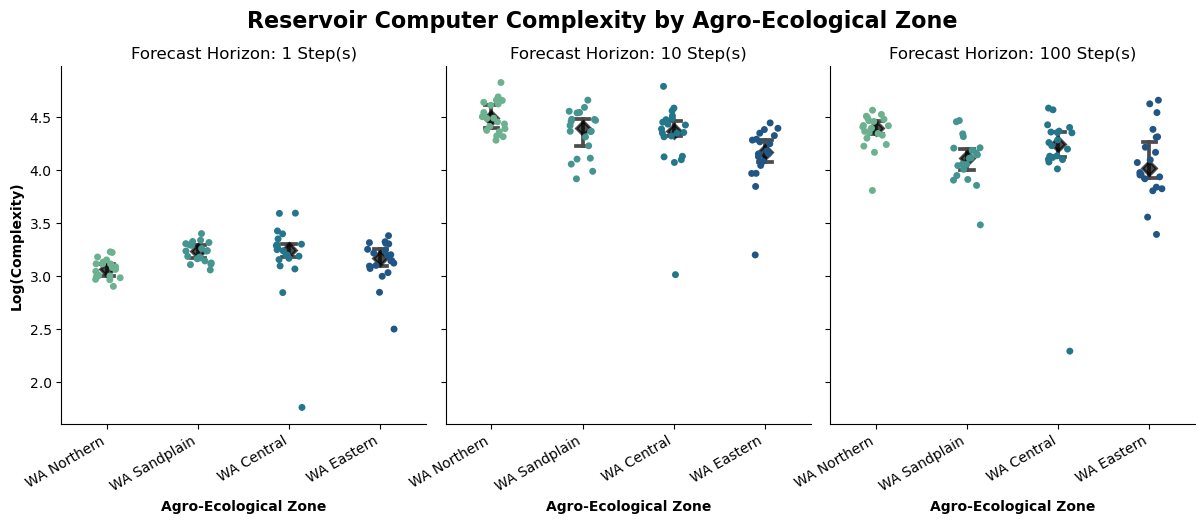

In [ ]:
# plot of the complexity scores for each of the zones based on forecast horizon
g = sns.catplot(data=metrics_df, x='Zone', y='Complexity', col='Step',
                kind='strip', palette='crest', hue='Zone',
                jitter=0.15, size=5,
                height=4.5, aspect=0.9, sharey=True)

for ax, step in zip(g.axes.flat, g.col_names):
    sns.pointplot(data=metrics_df[metrics_df.Step == step], x='Zone', y='Complexity', estimator='median', errorbar=('ci', 95),
                  color='black', linestyle='none', markers='D',
                  capsize=0.15, ax=ax, alpha=0.7)

g.set_xticklabels(rotation=30, ha='right', size=10)
g.set_titles('Forecast Horizon: {col_name} Step(s)', size=12)
g.figure.suptitle('Reservoir Computer Complexity by Agro-Ecological Zone', y=1.05, fontsize=16, fontweight='bold')
g.set_axis_labels('Agro-Ecological Zone', 'Log(Complexity)', fontweight='bold')
plt.savefig('Complexity_RegionPlot.png', bbox_inches='tight')
plt.show()

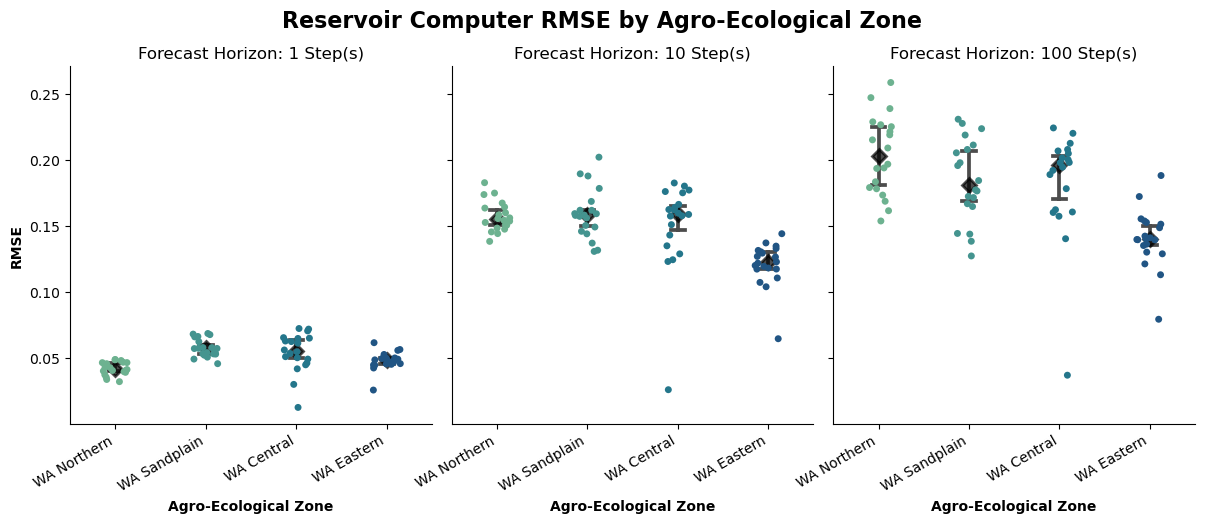

In [ ]:
# plot of the RMSE scores for each of the zones based on forecast horizon
g = sns.catplot(data=metrics_df, x='Zone', y='RMSE', col='Step',
                kind='strip', palette='crest', hue='Zone',
                jitter=0.15, size=5,
                height=4.5, aspect=0.9, sharey=True)

for ax, step in zip(g.axes.flat, g.col_names):
    sns.pointplot(data=metrics_df[metrics_df.Step == step], x='Zone', y='RMSE', estimator='median', errorbar=('ci', 95),
                  color='black', linestyle='none', markers='D',
                  capsize=0.15, ax=ax, alpha=0.7)

g.set_xticklabels(rotation=30, ha='right', size=10)
g.set_titles('Forecast Horizon: {col_name} Step(s)', size=12)
g.figure.suptitle('Reservoir Computer RMSE by Agro-Ecological Zone', y=1.05, fontsize=16, fontweight='bold')
g.set_axis_labels('Agro-Ecological Zone', 'RMSE', fontweight='bold')
plt.savefig('RMSE_RegionPlot.png',bbox_inches='tight')
plt.show()


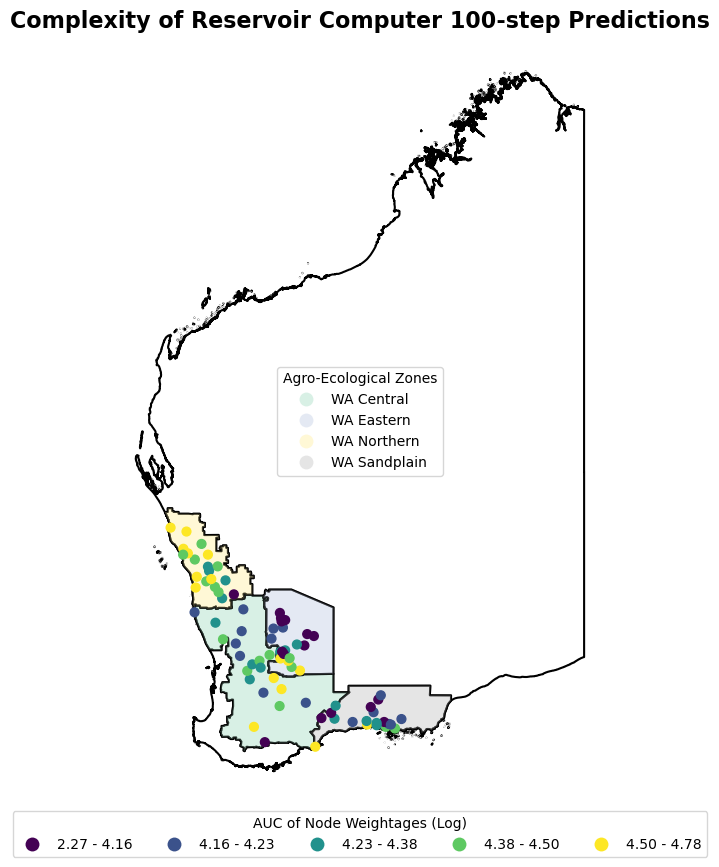

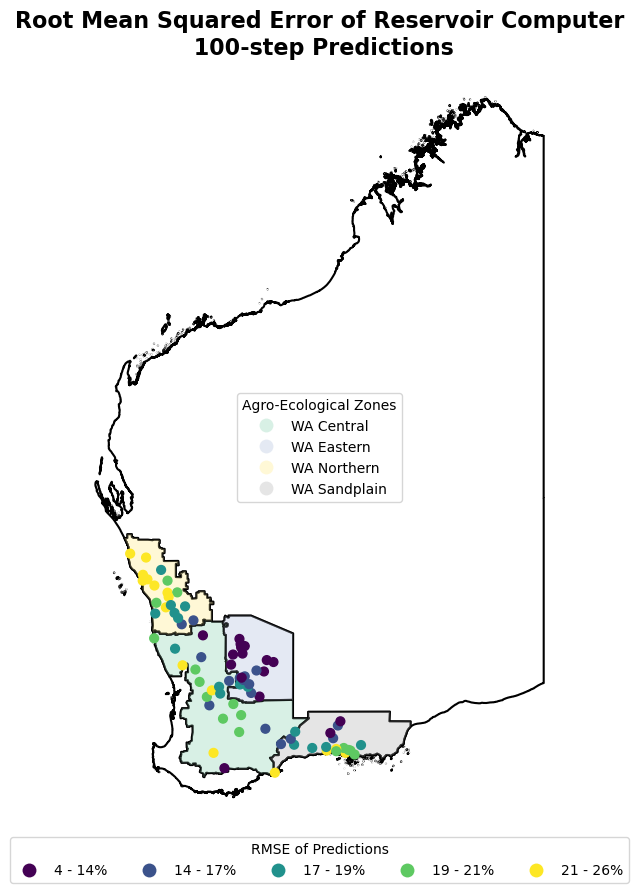

In [ ]:
# read in the shapefile for a map of Australia
aus_map = gpd.read_file('DATAFILES/STE_2026_AUST_SHP_GDA2020/STE_2026_AUST_GDA2020.shp')
#aus_map.head()
# filter to only plot WA
wa = aus_map[aus_map['STE_NAME26'] == 'Western Australia']
wa_map = wa.to_crs('GDA94')
# read in file with AEZs 
agro_zones = gpd.read_file('DATAFILES/aez(1).geojson')
# filter to only contain WA AEZs
condition1 = agro_zones['name'].str.contains('WA', case=True)
# omit zones WA Mallee and WA Ord
condition2 = ~agro_zones['name'].str.contains('WA Mallee|WA Ord', case=True)
wa_agro = agro_zones[condition1 & condition2]
wa_agro_map = wa_agro.to_crs('GDA94')


metrics_gdf = gpd.GeoDataFrame(data=metrics_df,
                               geometry=gpd.points_from_xy(metrics_df.Long,metrics_df.Lat),
                               crs='GDA94')



fig, ax = plt.subplots(figsize=(10, 10))
wa_map.plot(ax=ax, facecolor='none', edgecolor='black', linewidth=1.5)
wa_agro_map.plot(ax=ax, facecolor='none', edgecolor='black', linewidth=1.5)
wa_agro_map.plot(ax=ax, 
                 column='name',
                 cmap='Pastel2',
                 alpha=0.5,
                 edgecolor='black', 
                 linewidth=1.5, 
                 legend=True,
                 legend_kwds={'title':'Agro-Ecological Zones','loc':'center'})
agro_legend = ax.get_legend()
metrics_gdf[metrics_gdf.Step == 100].plot(ax=ax, markersize=40,marker='o',
                               column = 'Complexity',
                               cmap = 'viridis',
                               scheme = 'quantiles',
                               k=5,
                               legend=True,
                               legend_kwds = {'title': 'AUC of Node Weightages (Log)',
                                              'loc':'lower center',
                                              'bbox_to_anchor':(0.5,-0.075),
                                              'ncol':5,
                                              'frameon': True})
comp_legend = ax.get_legend()
custom_labels = ['2.27 - 4.16','4.16 - 4.23','4.23 - 4.38','4.38 - 4.50','4.50 - 4.78']
for text, new_label in zip(comp_legend.get_texts(), custom_labels):
    text.set_text(new_label)
ax.add_artist(agro_legend)
ax.set_xticks([])
ax.set_yticks([])
plt.box(False)
plt.title('Complexity of Reservoir Computer 100-step Predictions', size=16, fontweight='bold')
plt.savefig('Map_Complexity')
plt.show()



fig, ax = plt.subplots(figsize=(10, 10))
wa_map.plot(ax=ax, facecolor='none', edgecolor='black', linewidth=1.5)
wa_agro_map.plot(ax=ax, facecolor='none', edgecolor='black', linewidth=1.5)
wa_agro_map.plot(ax=ax, 
                 column='name',
                 cmap='Pastel2',
                 alpha=0.5,
                 edgecolor='black',
                 linewidth=1.5, 
                 legend=True,
                 legend_kwds={'title':'Agro-Ecological Zones','loc':'center'})
agro_legend = ax.get_legend()
metrics_gdf[metrics_gdf.Step == 100].plot(ax=ax, markersize=40,marker='o',
                               column = 'RMSE',
                               cmap = 'viridis',
                               scheme='quantiles',
                               k=5,
                               legend=True,
                               legend_kwds = {'title': 'RMSE of Predictions', 
                                              'loc':'lower center',
                                              'bbox_to_anchor':(0.5,-0.075),
                                              'ncol':5,
                                              'frameon': True})
rmse_legend = ax.get_legend()
custom_labels = ['4 - 14%','14 - 17%','17 - 19%','19 - 21%','21 - 26%']
for text, new_label in zip(rmse_legend.get_texts(), custom_labels):
    text.set_text(new_label)
ax.add_artist(agro_legend)
ax.set_xticks([])
ax.set_yticks([])
plt.box(False)
plt.title('Root Mean Squared Error of Reservoir Computer\n 100-step Predictions',size=16, fontweight='bold')
plt.savefig('Map_RMSE')
plt.show()


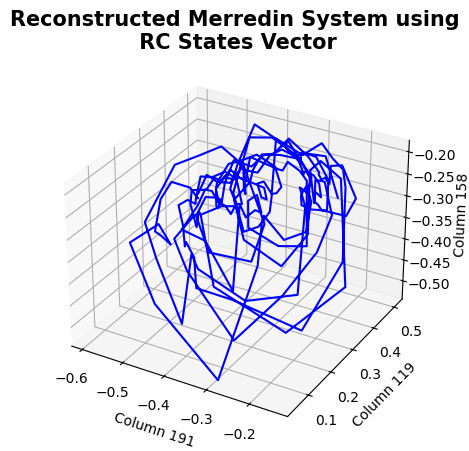

In [ ]:
# RC states based reconstruction
merredin_states = rc_for_location(esn, "Merredin", merre_rain, merre_gddc, step=100, plotting=False)

# plotting and 3 nodes from the 300 available
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
fig.subplots_adjust(left=0.05, right=0.95, top=0.9, bottom=0.1)
ax.plot3D(merredin_states[10:,191], merredin_states[10:,119], merredin_states[10:,158], 'blue')
ax.set_xlabel('Column 191')
ax.set_ylabel('Column 119')
ax.set_zlabel('Column 158')
ax.set_title('Reconstructed Merredin System using\n RC States Vector',fontweight='bold',size=15)
plt.savefig('RC_Reconstruction_Merre.png')
plt.show()
